In [4]:
setwd("/Users/ashleybelknap/Library/CloudStorage/OneDrive-TexasA&MAgriLife/Barboza Lab Shared/PCH_CaribouForage/NIR_CBforage/R files/scripts")

In [5]:
library(tidyverse)
library(fs)

In [6]:
# ---------------- CONFIG ----------------
spectra_dir <- "/Users/ashleybelknap/Library/CloudStorage/OneDrive-TexasA&MAgriLife/Barboza Lab Shared/PCH_CaribouForage/NIR_CBforage/R files/spectra"
inventory_path <- "/Users/ashleybelknap/Library/CloudStorage/OneDrive-TexasA&MAgriLife/Barboza Lab Shared/PCH_CaribouForage/NIR_CBforage/R files/spectra/master_inventory.csv"  
sample_id_col <- "sample_id"
output_path   <- "/Users/ashleybelknap/Library/CloudStorage/OneDrive-TexasA&MAgriLife/Barboza Lab Shared/PCH_CaribouForage/NIR_CBforage/R files/combined_long.csv"

In [7]:
spectra_paths <- dir_ls(spectra_dir, regexp = "\\.csv$")
spectra_paths <- spectra_paths[!str_detect(spectra_paths, "master_inventory")]
length(spectra_paths)  # should now be 19

[1] 19

In [8]:
load_one_spectra_file <- function(path) {
  df <- read_csv(path, show_col_types = FALSE, name_repair = "unique_quiet")

  # Standardize first column name regardless of label
  names(df)[1] <- "wavelength"
  df <- df %>% mutate(wavelength = as.numeric(wavelength))

  # Strip stray quotes AND the "...123" suffix readr adds for duplicate names
  clean_names <- names(df) %>%
    str_remove_all('"') %>%
    str_remove("\\.\\.\\.\\d+$")
  names(df) <- clean_names
  names(df)[1] <- "wavelength"  # reapply in case regex touched it

  long_df <- df %>%
    pivot_longer(cols = -wavelength, names_to = "sample_id", values_to = "intensity") %>%
    mutate(
      sample_id = str_trim(sample_id),
      source_file = basename(path)
    )

  # Flag duplicates WITHIN this file (same sample_id + wavelength appearing >1x)
  dup_flag <- long_df %>%
    count(sample_id, wavelength) %>%
    filter(n > 1)

  if (nrow(dup_flag) > 0) {
    dup_ids <- unique(dup_flag$sample_id)
    message(sprintf("  ⚠ [%s] duplicate sample IDs found (likely replicate scans): %s",
                     basename(path), paste(dup_ids, collapse = ", ")))
  }

  # Add a replicate counter per (sample_id, wavelength) so duplicates are traceable, not silently merged
  long_df <- long_df %>%
    group_by(sample_id, wavelength) %>%
    mutate(replicate = row_number()) %>%
    ungroup()

  long_df
}


In [9]:
# ---- Load + combine all 19 spectra files ----
spectra_paths <- dir_ls(spectra_dir, regexp = "\\.csv$")
spectra_paths <- spectra_paths[!str_detect(spectra_paths, "master_inventory")]
message(sprintf("Found %d spectra files", length(spectra_paths)))

spectra_long <- map_dfr(spectra_paths, function(p) {
  message(paste("Loading", basename(p), "..."))
  load_one_spectra_file(p)
})

message(sprintf("\nCombined spectra: %s rows, %d unique samples",
                format(nrow(spectra_long), big.mark = ","),
                n_distinct(spectra_long$sample_id)))
message(sprintf("Wavelength range in data: %s to %s",
                min(spectra_long$wavelength, na.rm = TRUE),
                max(spectra_long$wavelength, na.rm = TRUE)))

Found 19 spectra files

Loading CoastalSpeciesSpectra.csv ...



Loading Sari_spectra.csv ...

Loading a072226spectra.csv ...

Loading a072426spectra.csv ...

Loading a072726spectra.csv ...

Loading a072926spectra.csv ...

Loading bena_spectra.csv ...

Loading caaq_spectra.csv ...

Loading cabi_spectra.csv ...

Loading erva_spectra.csv ...

  ⚠ [erva_spectra.csv] duplicate sample IDs found (likely replicate scans): AB073, AB075, AB076

Loading f072026spectra.csv ...

Loading f073026spectra.csv ...

Loading f073126spectra.csv ...

Loading f081026spectra.csv ...

Loading f081126spectra.csv ...

Loading f081226spectra.csv ...

Loading f081326spectra.csv ...

Loading pela_spectra.csv ...

Loading sapu_spectra.csv ...


Combined spectra: 2,102,100 rows, 1998 unique samples

Wavelength range in data: 400 to 2498



In [10]:
range_by_file <- spectra_long %>%
  group_by(source_file) %>%
  summarize(min_wl = min(wavelength), max_wl = max(wavelength)) %>%
  arrange(desc(max_wl))

print(range_by_file, n = 19)

# A tibble: 19 × 3
   source_file               min_wl max_wl
   <chr>                      <dbl>  <dbl>
 1 CoastalSpeciesSpectra.csv    400   2498
 2 Sari_spectra.csv             400   2498
 3 a072226spectra.csv           400   2498
 4 a072426spectra.csv           400   2498
 5 a072726spectra.csv           400   2498
 6 a072926spectra.csv           400   2498
 7 bena_spectra.csv             400   2498
 8 caaq_spectra.csv             400   2498
 9 cabi_spectra.csv             400   2498
10 erva_spectra.csv             400   2498
11 f072026spectra.csv           400   2498
12 f073026spectra.csv           400   2498
13 f073126spectra.csv           400   2498
14 f081026spectra.csv           400   2498
15 f081126spectra.csv           400   2498
16 f081226spectra.csv           400   2498
17 f081326spectra.csv           400   2498
18 pela_spectra.csv             400   2498
19 sapu_spectra.csv             400   2498


In [11]:
spectra_long %>%
  filter(source_file == "erva_spectra.csv", sample_id %in% c("AB073", "AB075", "AB076"), wavelength == 400) %>%
  arrange(sample_id, replicate)

wavelength,sample_id,intensity,source_file,replicate
<dbl>,<chr>,<dbl>,<chr>,<int>
400,AB073,0.4337457,erva_spectra.csv,1
400,AB073,0.4422797,erva_spectra.csv,2
400,AB075,0.4536456,erva_spectra.csv,1
400,AB075,0.4827339,erva_spectra.csv,2
400,AB076,0.4775937,erva_spectra.csv,1
400,AB076,0.4142182,erva_spectra.csv,2


In [12]:
# Average replicate scans within the same file
spectra_avg <- spectra_long %>%
  group_by(sample_id, wavelength, source_file) %>%
  summarize(
    intensity = mean(intensity),
    n_replicates = n(),
    .groups = "drop"
  )

message(sprintf("After averaging replicates: %s rows, %d unique samples",
                format(nrow(spectra_avg), big.mark = ","),
                n_distinct(spectra_avg$sample_id)))



After averaging replicates: 2,098,950 rows, 1998 unique samples



In [13]:
# Any sample appearing across MULTIPLE source files?
cross_file_dupes <- spectra_avg %>%
  distinct(sample_id, source_file) %>%
  count(sample_id) %>%
  filter(n > 1)

if (nrow(cross_file_dupes) > 0) {
  message(sprintf("  ⚠ %d sample ID(s) appear in MORE THAN ONE source file: %s",
                   nrow(cross_file_dupes),
                   paste(head(cross_file_dupes$sample_id, 10), collapse = ", ")))
} else {
  message("No sample IDs appear in more than one source file — good.")
}


  ⚠ 1 sample ID(s) appear in MORE THAN ONE source file: AB1909



In [14]:
# ---- Load inventory ----
inventory <- read_csv(inventory_path, show_col_types = FALSE)
inventory <- inventory %>%
  mutate(!!sample_id_col := str_trim(as.character(.data[[sample_id_col]])))

message(sprintf("\nInventory: %d rows, %d unique samples",
                nrow(inventory), n_distinct(inventory[[sample_id_col]])))


Inventory: 1999 rows, 1999 unique samples



In [15]:
 #---- Check ID match BEFORE merging ----
spectra_ids   <- unique(spectra_avg$sample_id)
inventory_ids <- unique(inventory[[sample_id_col]])

only_in_spectra   <- setdiff(spectra_ids, inventory_ids)
only_in_inventory <- setdiff(inventory_ids, spectra_ids)

message(sprintf("\n%d sample IDs in spectra but NOT in inventory", length(only_in_spectra)))
if (length(only_in_spectra) > 0) print(only_in_spectra)

message(sprintf("%d sample IDs in inventory but NOT in spectra", length(only_in_inventory)))
if (length(only_in_inventory) > 0) print(only_in_inventory)




0 sample IDs in spectra but NOT in inventory

1 sample IDs in inventory but NOT in spectra



[1] "AB1841"


In [16]:
# ---- Merge ----
combined <- spectra_avg %>%
  left_join(inventory, by = sample_id_col)

message(sprintf("\nFinal combined dataset: %s rows", format(nrow(combined), big.mark = ",")))
write_csv(combined, output_path)
message(paste("Saved to", output_path))


Final combined dataset: 2,098,950 rows

Saved to /Users/ashleybelknap/Library/CloudStorage/OneDrive-TexasA&MAgriLife/Barboza Lab Shared/PCH_CaribouForage/NIR_CBforage/R files/combined_long.csv



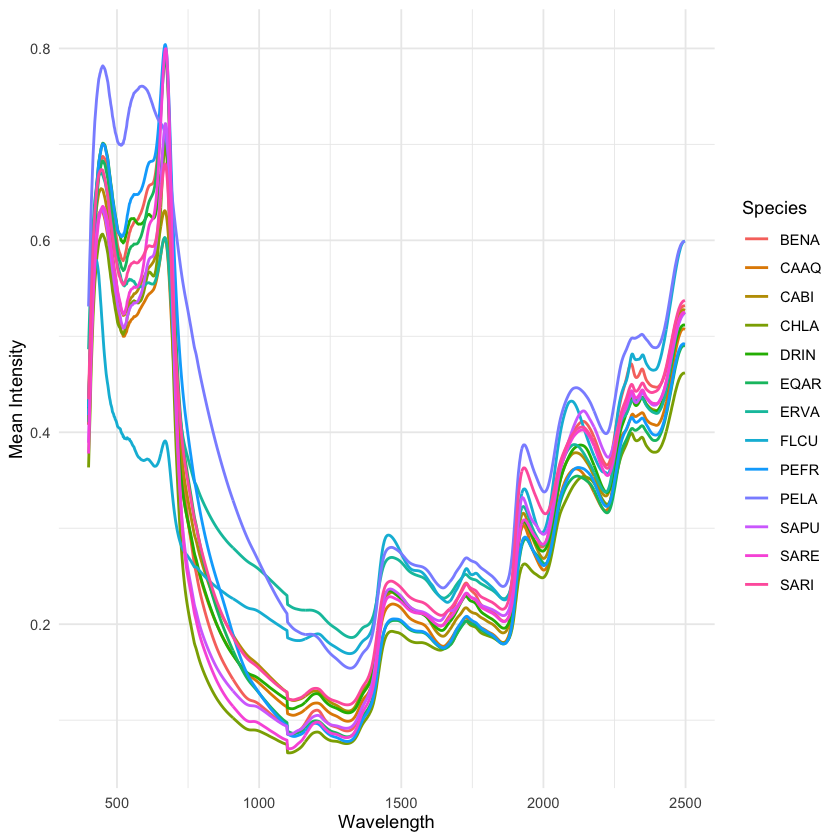

In [17]:
species_mean <- combined %>%
  group_by(species, wavelength) %>%     # replace 'species' with your actual column name
  summarize(mean_intensity = mean(intensity, na.rm = TRUE), .groups = "drop")

ggplot(species_mean, aes(x = wavelength, y = mean_intensity, color = species)) +
  geom_line(linewidth = 0.8) +
  labs(x = "Wavelength", y = "Mean Intensity", color = "Species") +
  theme_minimal()